In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

I0000 00:00:1794226782.423154   57475 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794226782.569062   57475 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794226784.101726   57475 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
dataset_path = "/home/lokesh/Loki/Projects/GEN AI/Face mask detection/dataset"

In [3]:
X = []
y = []

categories = ["with_mask", "without_mask"]

for label, category in enumerate(categories):

    folder_path = os.path.join(dataset_path, category)

    for image_name in os.listdir(folder_path):

        image_path = os.path.join(folder_path, image_name)

        try:
            image = keras.utils.load_img(
                image_path,
                target_size=(128, 128)
            )

            image = keras.utils.img_to_array(image)

            X.append(image)
            y.append(label)

        except Exception as e:
            print("Skipping:", image_name)

X = np.array(X, dtype=np.float32)
y = np.array(y)

print(X.shape)
print(y.shape)

/home/lokesh/Loki/Projects/GEN AI/.venv/lib/python3.14/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


(3846, 128, 128, 3)
(3846,)


In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [5]:
X_train = preprocess_input(X_train)
X_val = preprocess_input(X_val)
X_test = preprocess_input(X_test)

In [6]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

E0000 00:00:1794226831.424892   57475 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [7]:
base_model.trainable = False

In [8]:
model = keras.Sequential([

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")

])

In [9]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [10]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    batch_size=16,
    epochs=10,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/10


W0000 00:00:1794226985.818053   57475 cpu_allocator_impl.cc:174] Allocation of 529268736 exceeds 10% of free system memory.


  2/169 ━━━━━━━━━━━━━━━━━━━━ 15s 92ms/step - accuracy: 0.7188 - loss: 0.7134

W0000 00:00:1794226990.338389   57540 cpu_allocator_impl.cc:174] Allocation of 25165824 exceeds 10% of free system memory.
W0000 00:00:1794226990.352454   57540 cpu_allocator_impl.cc:174] Allocation of 25958400 exceeds 10% of free system memory.
W0000 00:00:1794226990.437777   57541 cpu_allocator_impl.cc:174] Allocation of 25165824 exceeds 10% of free system memory.
W0000 00:00:1794226990.451767   57541 cpu_allocator_impl.cc:174] Allocation of 25958400 exceeds 10% of free system memory.


169/169 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - accuracy: 0.9699 - loss: 0.0851 - val_accuracy: 0.9809 - val_loss: 0.0467
Epoch 2/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - accuracy: 0.9918 - loss: 0.0242 - val_accuracy: 0.9913 - val_loss: 0.0314
Epoch 3/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - accuracy: 0.9889 - loss: 0.0394 - val_accuracy: 0.9913 - val_loss: 0.0331
Epoch 4/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - accuracy: 0.9941 - loss: 0.0187 - val_accuracy: 0.9931 - val_loss: 0.0206
Epoch 5/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - accuracy: 0.9929 - loss: 0.0174 - val_accuracy: 0.9896 - val_loss: 0.0305
Epoch 6/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - accuracy: 0.9963 - loss: 0.0092 - val_accuracy: 0.9965 - val_loss: 0.0080
Epoch 7/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - accuracy: 0.9974 - loss: 0.0087 - val_accuracy: 0.9948 - val_loss: 0.0149
Epoch 8/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - accuracy: 0.9989 - loss: 0.0038 - val

In [11]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 188ms/step - accuracy: 0.9913 - loss: 0.0312
Test Accuracy: 0.9913344979286194
Test Loss: 0.031242311000823975


In [12]:
y_pred = model.predict(X_test)

y_pred = (y_pred >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=["With Mask", "Without Mask"]
))

19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 221ms/step
              precision    recall  f1-score   support

   With Mask       0.99      0.99      0.99       288
Without Mask       0.99      0.99      0.99       289

    accuracy                           0.99       577
   macro avg       0.99      0.99      0.99       577
weighted avg       0.99      0.99      0.99       577



In [13]:
model.save("face_mask_mobilenetv2.keras")

In [14]:
model = keras.models.load_model(
    "face_mask_mobilenetv2.keras"
)

19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 243ms/step


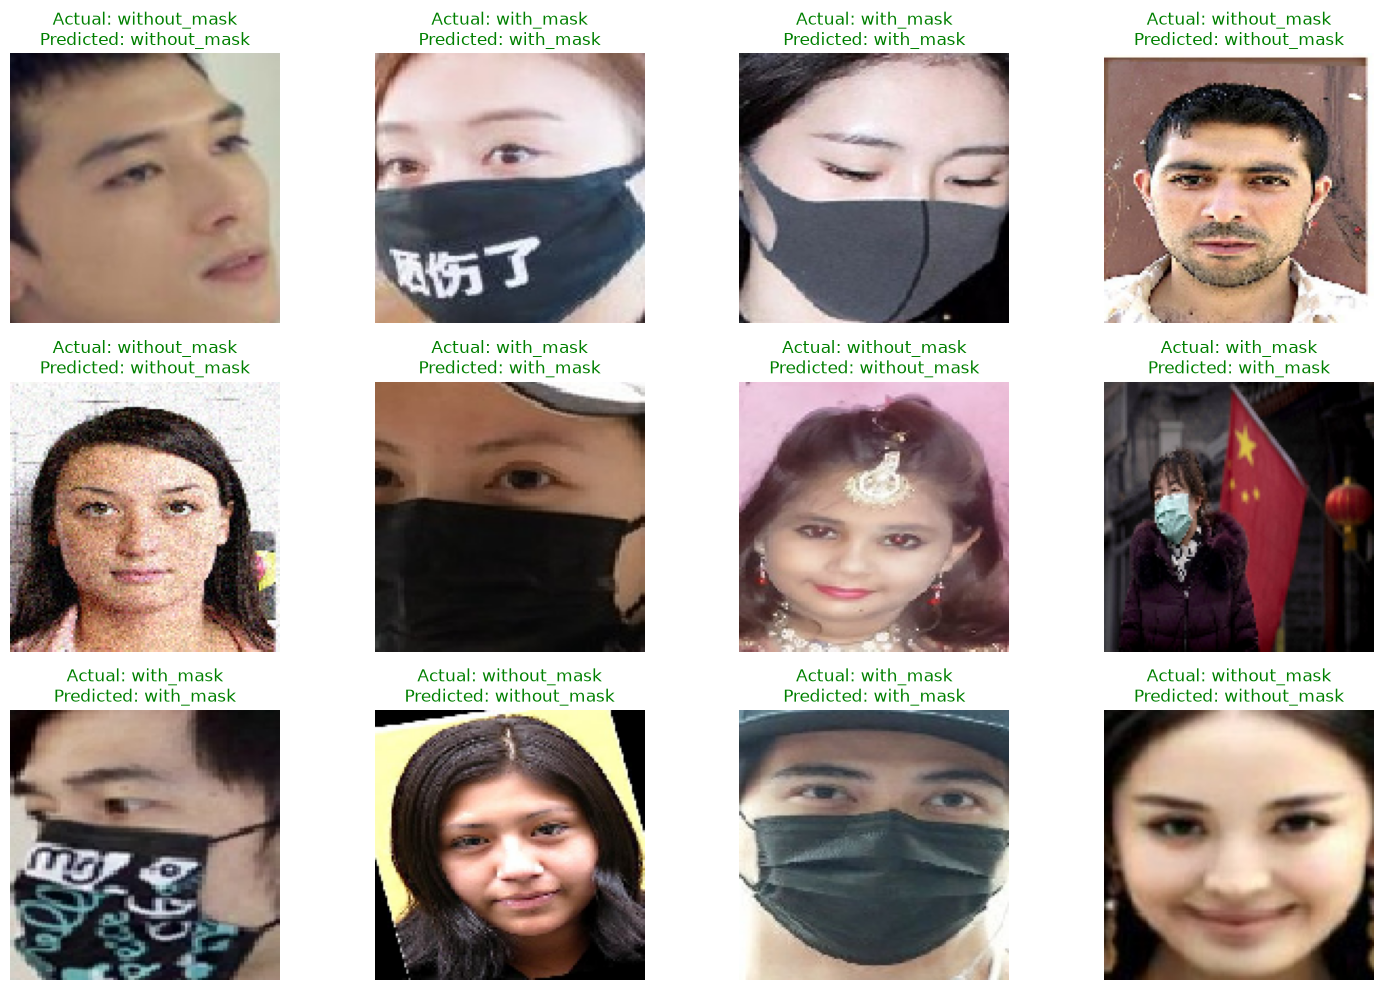

In [17]:

import random

# Get predictions from the test dataset
predictions = model.predict(X_test)

# Convert probabilities into class labels
predicted_labels = (predictions >= 0.5).astype(int).flatten()

# Display 12 random test images
plt.figure(figsize=(15, 10))

for i in range(12):

    index = random.randint(0, len(X_test) - 1)

    # Convert preprocessed image back to display format
    image = (X_test[index] + 1.0) * 127.5
    image = np.clip(image, 0, 255).astype("uint8")

    actual = y_test[index]
    predicted = predicted_labels[index]

    actual_name = categories[actual]
    predicted_name = categories[predicted]

    color = "green" if actual == predicted else "red"

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {actual_name}\nPredicted: {predicted_name}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


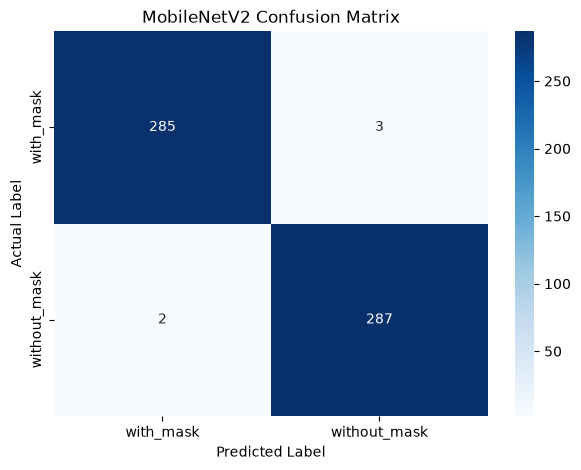

              precision    recall  f1-score   support

   with_mask       0.99      0.99      0.99       288
without_mask       0.99      0.99      0.99       289

    accuracy                           0.99       577
   macro avg       0.99      0.99      0.99       577
weighted avg       0.99      0.99      0.99       577



In [18]:

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predicted_labels)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=categories,
    yticklabels=categories
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MobileNetV2 Confusion Matrix")

plt.show()

print(classification_report(
    y_test,
    predicted_labels,
    target_names=categories
))


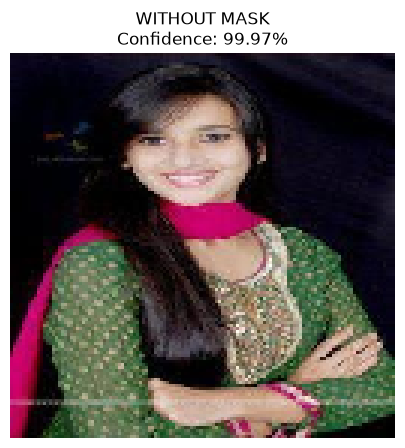

Prediction: WITHOUT MASK
Confidence: 99.97%


In [21]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Change this to the path of your test image
image_path = "/home/lokesh/Loki/Projects/GEN AI/Face mask detection/dataset/without_mask/0.jpg"

# Load image
image = keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

image_array = keras.utils.img_to_array(image)

# Apply MobileNetV2 preprocessing
image_array = preprocess_input(
    np.expand_dims(image_array, axis=0)
)

# Predict
prediction = model.predict(image_array, verbose=0)[0][0]

# Interpret prediction
if prediction >= 0.5:
    result = "WITHOUT MASK"
    confidence = prediction * 100
else:
    result = "WITH MASK"
    confidence = (1 - prediction) * 100

# Display result
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(
    f"{result}\nConfidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print("Prediction:", result)
print("Confidence:", f"{confidence:.2f}%")


In [23]:
import cv2
import numpy as np
from tensorflow import keras

In [24]:
print([name for name in dir(cv2) if "Cascade" in name])

['BaseCascadeClassifier', 'CascadeClassifier', 'CascadeClassifier_convert']


In [25]:
model = keras.models.load_model("face_mask_mobilenetv2.keras")

In [26]:
print(hasattr(cv2, "objdetect"))

False


In [27]:
face_detector = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

In [28]:
cap = cv2.VideoCapture(0)

print("Camera available:", cap.isOpened())

cap.release()

Camera available: True


In [34]:

import cv2
import numpy as np

# Open webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open webcam")

else:
    print("Webcam started!")
    print("Press Q to quit.")

    try:
        while True:

            # Capture continuous frames
            ret, frame = cap.read()

            if not ret:
                print("Cannot read webcam frame")
                break

            # Convert frame to grayscale
            gray = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2GRAY
            )

            # Detect faces
            faces = face_detector.detectMultiScale(
                gray,
                scaleFactor=1.1,
                minNeighbors=5,
                minSize=(30, 30)
            )

            # Process every detected face
            for (x, y, w, h) in faces:

                # Crop face from original frame
                face = frame[y:y+h, x:x+w]

                # Convert BGR to RGB
                face = cv2.cvtColor(
                    face,
                    cv2.COLOR_BGR2RGB
                )

                # Resize to CNN input size
                face = cv2.resize(
                    face,
                    (128, 128)
                )

                # Convert to float32
                face = face.astype("float32")

                # Add batch dimension
                face = np.expand_dims(face, axis=0)
                
                # Apply the SAME preprocessing used during training
                face = preprocess_input(face)

                # Predict using CNN
                prediction = model.predict(
                    face,
                    verbose=0
                )[0][0]

                # Classification
                if prediction >= 0.5:
                    label = "NO MASK"
                    confidence = prediction * 100
                    color = (0, 0, 255)

                else:
                    label = "MASK"
                    confidence = (1 - prediction) * 100
                    color = (0, 255, 0)

                # Draw rectangle
                cv2.rectangle(
                    frame,
                    (x, y),
                    (x+w, y+h),
                    color,
                    2
                )

                # Display classification
                text = f"{label}: {confidence:.1f}%"

                cv2.putText(
                    frame,
                    text,
                    (x, y-10),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    color,
                    2
                )

            # Display live webcam
            cv2.imshow(
                "Face Mask Detection",
                frame
            )

            # Press Q to quit
            if cv2.waitKey(1) & 0xFF == ord('q'):
                break

    finally:
        cap.release()
        cv2.destroyAllWindows()

        print("Webcam stopped.")


Webcam started!
Press Q to quit.
Cannot read webcam frame
Webcam stopped.


[ WARN:0@4326.579] global cap_v4l.cpp:804 requestBuffers VIDEOIO(V4L2:/dev/video0): failed VIDIOC_REQBUFS: errno=19 (No such device)
